Постановка задачи

Банк хочет автоматизировать отбор клиентов для кампаний прямого маркетинга по срочным депозитам, чтобы заранее прогнозировать, согласится ли клиент открыть депозит, и направлять усилия колл-центра только на перспективные контакты. Для этого он опубликовал набор данных, который включает 41 188 строк и 21 столбец (20 признаков и целевая переменная).

Названия столбцов с пояснением:

- **age** — Возраст клиента
- **job** — Профессия *(admin., blue-collar, entrepreneur, housemaid, management, retired, self-employed, services, student, technician, unemployed, unknown)*
- **marital** — Семейное положение *(divorced, married, single, unknown)*
- **education** — Уровень образования *(basic.4y, basic.6y, basic.9y, high.school, illiterate, professional.course, university.degree, unknown)*
- **default** — Есть ли просроченный кредит *(yes, no, unknown)*
- **housing** — Есть ли ипотечный кредит *(yes, no, unknown)*
- **loan** — Есть ли потребительский кредит *(yes, no, unknown)*
- **contact** — Тип связи при контакте *(cellular, telephone)*
- **month** — Месяц последнего контакта *(jan, feb, mar, apr, may, jun, jul, aug, sep, oct, nov, dec)*
- **day_of_week** — День недели последнего контакта *(mon, tue, wed, thu, fri)*
- **duration** — Длительность последнего звонка в секундах
- **campaign** — Число контактов с клиентом в текущей кампании
- **pdays** — Число дней с последнего контакта
- **previous** — Число контактов до текущей кампании
- **poutcome** — Итог предыдущей кампании *(failure, nonexistent, success)*
- **emp.var.rate** — Коэффициент вариации занятости
- **cons.price.idx** — Индекс потребительских цен
- **cons.conf.idx** — Индекс потребительской уверенности
- **euribor3m** — Ставка Euribor на 3 месяца
- **nr.employed** — Число занятых в экономике
- **y** — Открыл ли клиент срочный депозит *(yes, no)*


Импорт основных библиотек

In [354]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [355]:
import numpy as np
import pandas as pd
import seaborn as sns
import phik
import matplotlib.pyplot as plt
import random
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split

In [356]:
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

1. Изучение структуры данных 

In [357]:
df = pd.read_csv("bank-additional-full.csv", sep=";")
df.head(5)

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [358]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

Здесь видно, что ни в одном из признаков нет пропусков. Количество признаков типа object примерно такое же как и признаков int/float. 

In [359]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


2. Проверка на корректность и качество данных

2.1 Проверка на дубликаты

In [360]:
df.duplicated().sum()

np.int64(12)

12 объектов в датасете полностью копируют друг друга. Их нужно будет удалить и оставить только неповторяющиеся объекты.

2.2 Проверка на пропуски

In [361]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Пропусков в датасете нет

2.3 Корректность по столбцам

In [362]:
#Проверим, что значения числовых признаков корректны
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


Тут явно где-то есть выбросы, это можно понять по значениям max, например, у duration, campaign, previous. Однако в целом все значения корректны по смыслу

In [363]:
#Начнем проверять категориальные признаки
df["job"].value_counts()

job
admin.           10422
blue-collar       9254
technician        6743
services          3969
management        2924
retired           1720
entrepreneur      1456
self-employed     1421
housemaid         1060
unemployed        1014
student            875
unknown            330
Name: count, dtype: int64

Тут мы видим unknown = 330, это скрытые пропуски, которых не было видно на методе info(). Их нужно будет заполнить. 

In [364]:
#Проверяем все категориальные признаки на unknown

cat_columns = df.select_dtypes(include = ['object']).columns

for col in cat_columns:
    print(f"Анализ колонки: {col}")
    print((df[col] == "unknown").sum() / len(df))

Анализ колонки: job
0.008012042342429833
Анализ колонки: marital
0.0019423132951345051
Анализ колонки: education
0.042026803923472855
Анализ колонки: default
0.20872584247839177
Анализ колонки: housing
0.0240361270272895
Анализ колонки: loan
0.0240361270272895
Анализ колонки: contact
0.0
Анализ колонки: month
0.0
Анализ колонки: day_of_week
0.0
Анализ колонки: poutcome
0.0
Анализ колонки: y
0.0


По доле пропусков в категориальных признаках можно заметить, что наибольшее число пропусков находится в default, там 20% пропусков. Всего пропуски есть в 6 категориальных признаков

3. Детальное изучение признаков и таргета 

3.1 Числовые признаки

<Axes: xlabel='age', ylabel='Count'>

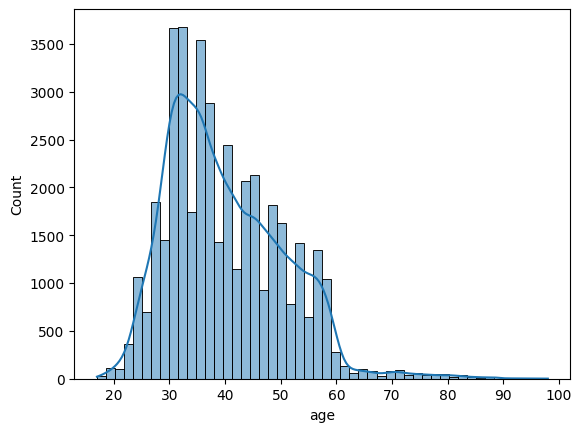

In [365]:
#Строим гистограмму распределения age
sns.histplot(data=df, x = "age", bins = 50, kde = True)

Видим, что основная масса значений находится в диапазоне от 25 до 56-59, остальное выбросы

**ВАЖНЫЙ МОМЕНТ**: признак duration является утечкой в данном датасете, так как длительность звонка неизвестна до звонка, 
а модель должна прогнозировать до контакта. Значит в реальном проде этой фичи в момент предсказания просто нет. После звонка таргет
уже известен, а значит duration детерменирует таргет. Модель будет лишь читать ответ, а не предсказывать. В моделировании данный признак 
использоваться не будет (даже для baseline так как метрики такого baseline будут бессмысленными)

<Axes: xlabel='campaign', ylabel='Count'>

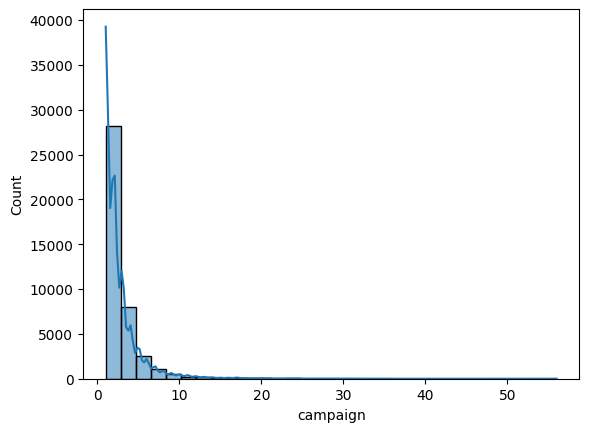

In [366]:
sns.histplot(data = df, x="campaign", bins = 30, kde = True)

In [367]:
df["campaign"].value_counts()

campaign
1     17642
2     10570
3      5341
4      2651
5      1599
6       979
7       629
8       400
9       283
10      225
11      177
12      125
13       92
14       69
17       58
16       51
15       51
18       33
20       30
19       26
21       24
22       17
23       16
24       15
27       11
29       10
28        8
26        8
25        8
31        7
30        7
35        5
32        4
33        4
34        3
42        2
40        2
43        2
56        1
39        1
41        1
37        1
Name: count, dtype: int64

Видим, что основная масса значений находится в диапазоне от 1 до 4, остальное выбросы

<Axes: xlabel='pdays', ylabel='Count'>

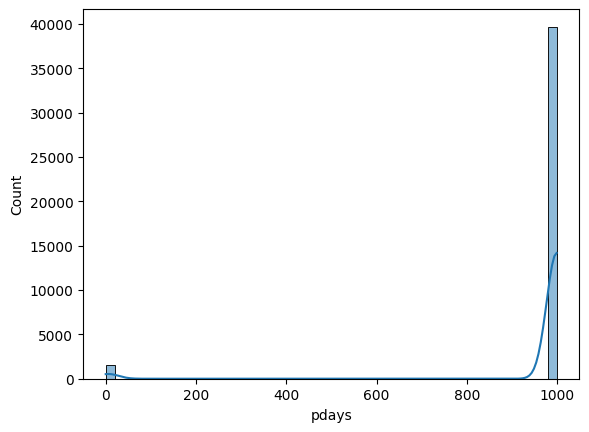

In [368]:
sns.histplot(data=df, x="pdays", bins=50, kde=True)

In [369]:
df["pdays"].value_counts()

pdays
999    39673
3        439
6        412
4        118
9         64
2         61
7         60
12        58
10        52
5         46
13        36
11        28
1         26
15        24
14        20
8         18
0         15
16        11
17         8
18         7
22         3
19         3
21         2
25         1
26         1
27         1
20         1
Name: count, dtype: int64

Видим, что основная масса значений находится в значении 999, остальное выбросы. Это значит, что с основной частью клиентов банк еще не 
взаимодействовал 

<Axes: xlabel='previous', ylabel='Count'>

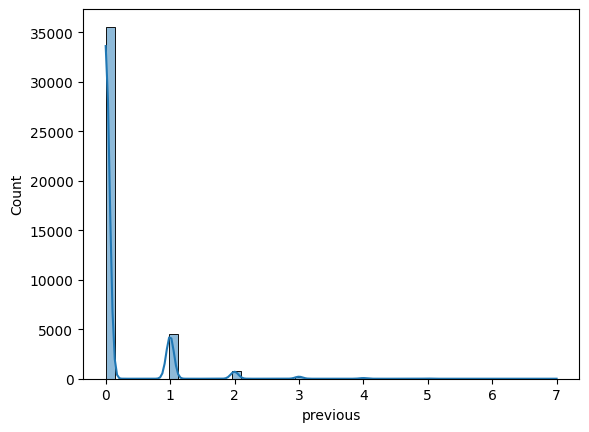

In [370]:
sns.histplot(data=df, x="previous", bins=50, kde=True)

In [371]:
df["previous"].value_counts()

previous
0    35563
1     4561
2      754
3      216
4       70
5       18
6        5
7        1
Name: count, dtype: int64

Видим, что основная масса значений находится в диапазоне от 0 до 1, остальное выбросы

<Axes: xlabel='emp.var.rate', ylabel='Count'>

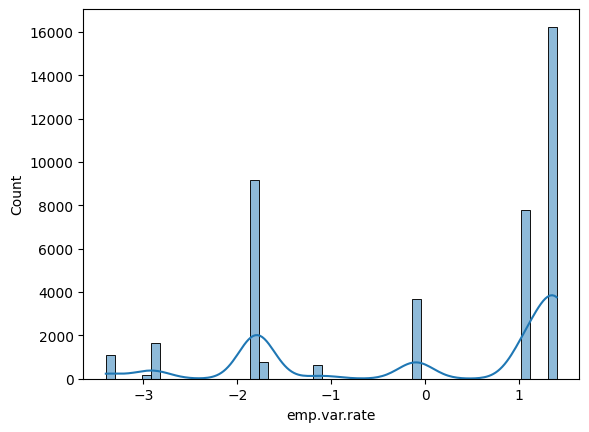

In [372]:
sns.histplot(data=df, x="emp.var.rate", bins=50, kde=True)

In [373]:
df["emp.var.rate"].value_counts()

emp.var.rate
 1.4    16234
-1.8     9184
 1.1     7763
-0.1     3683
-2.9     1663
-3.4     1071
-1.7      773
-1.1      635
-3.0      172
-0.2       10
Name: count, dtype: int64

Признак имеет как много положительных, так и отрицательных значений, есть выбросы. 
Данный признак привязан ко времени, не индивидуален для клиента.

<Axes: xlabel='cons.price.idx', ylabel='Count'>

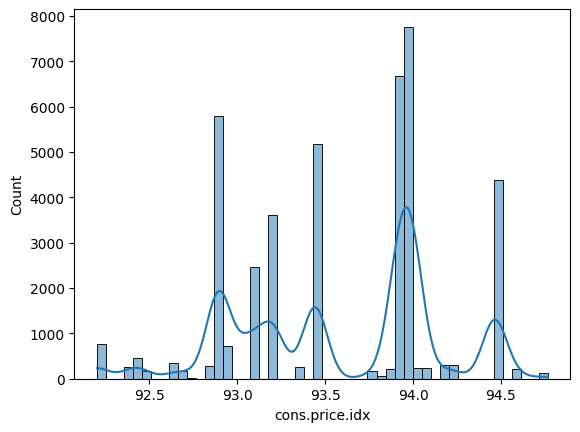

In [374]:
sns.histplot(data=df, x="cons.price.idx", bins=50, kde=True)

In [375]:
df["cons.price.idx"].value_counts()

cons.price.idx
93.994    7763
93.918    6685
92.893    5794
93.444    5175
94.465    4374
93.200    3616
93.075    2458
92.201     770
92.963     715
92.431     447
92.649     357
94.215     311
94.199     303
92.843     282
92.379     267
93.369     264
94.027     233
94.055     229
93.876     212
94.601     204
92.469     178
93.749     174
92.713     172
94.767     128
93.798      67
92.756      10
Name: count, dtype: int64

Данный признак так же привязан ко времени. По сути чем выше значение, тем больше шанс того, что клиент отдаст деньги на депозит или просто потратит, на данном этапе это лишь догадки

<Axes: xlabel='cons.conf.idx', ylabel='Count'>

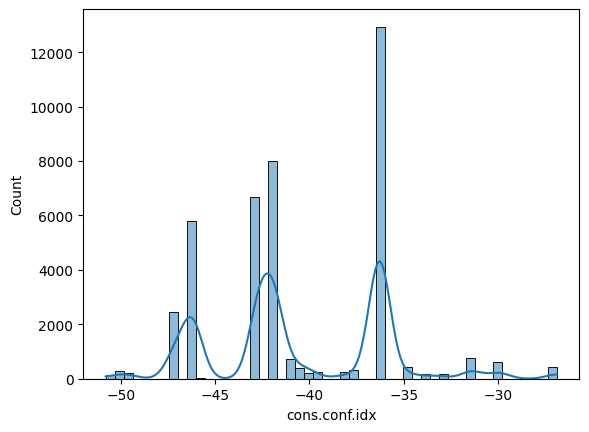

In [376]:
sns.histplot(data=df, x="cons.conf.idx", bins=50, kde=True)

In [377]:
df["cons.conf.idx"].value_counts()

cons.conf.idx
-36.4    7763
-42.7    6685
-46.2    5794
-36.1    5175
-41.8    4374
-42.0    3616
-47.1    2458
-31.4     770
-40.8     715
-26.9     447
-30.1     357
-40.3     311
-37.5     303
-50.0     282
-29.8     267
-34.8     264
-38.3     233
-39.8     229
-40.0     212
-49.5     204
-33.6     178
-34.6     174
-33.0     172
-50.8     128
-40.4      67
-45.9      10
Name: count, dtype: int64

Данный признак так же привязан ко времени, какого-то четкого распределения здесь нет

<Axes: xlabel='euribor3m', ylabel='Count'>

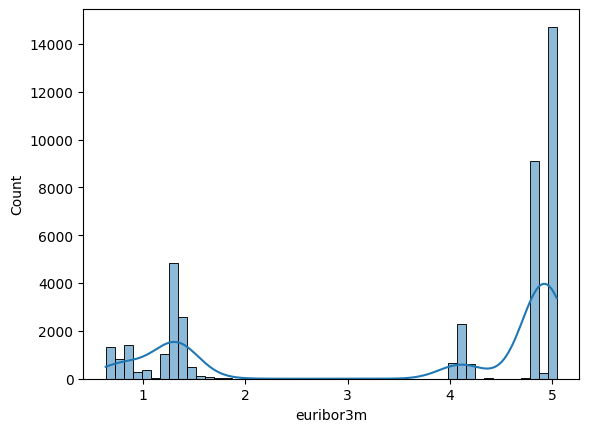

In [378]:
sns.histplot(data=df, x="euribor3m", bins=50, kde=True)

In [379]:
df["euribor3m"].value_counts()

euribor3m
4.857    2868
4.962    2613
4.963    2487
4.961    1902
4.856    1210
         ... 
3.853       1
3.901       1
0.969       1
0.956       1
3.669       1
Name: count, Length: 316, dtype: int64

Данный признак так же привязан ко времени, основные значения находятся в районе 4.8

<Axes: xlabel='nr.employed', ylabel='Count'>

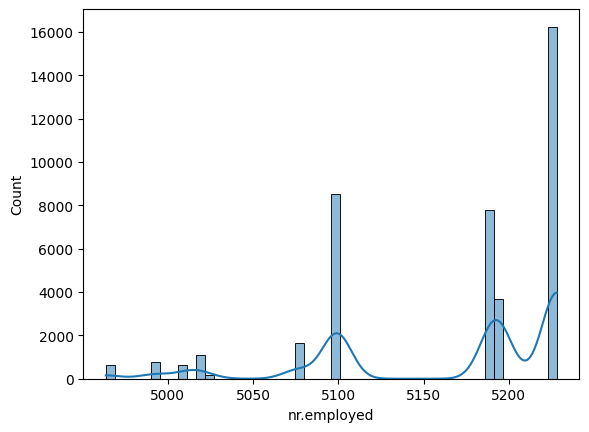

In [380]:
sns.histplot(data=df, x="nr.employed", bins=50, kde=True)

In [381]:
df["nr.employed"].value_counts()

nr.employed
5228.1    16234
5099.1     8534
5191.0     7763
5195.8     3683
5076.2     1663
5017.5     1071
4991.6      773
5008.7      650
4963.6      635
5023.5      172
5176.3       10
Name: count, dtype: int64

Данный признак так же привязан ко времени, основные значения находятся в районе 5000-5200

3.2 Категориальные признаки

<Axes: xlabel='count', ylabel='job'>

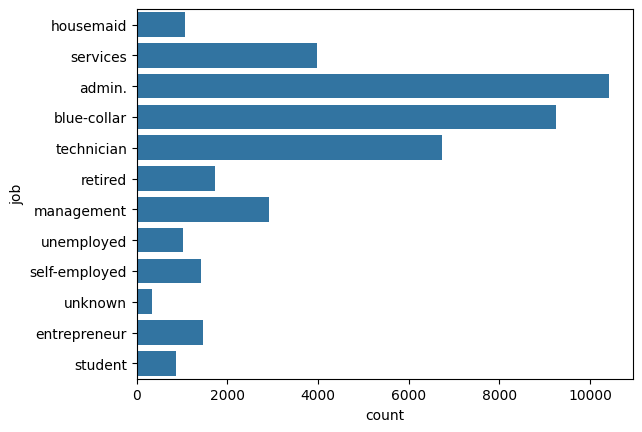

In [382]:
sns.countplot(data=df, y="job")

Большинство людей - обслуживающий персонал, рабочие и технические специалисты

<Axes: xlabel='count', ylabel='marital'>

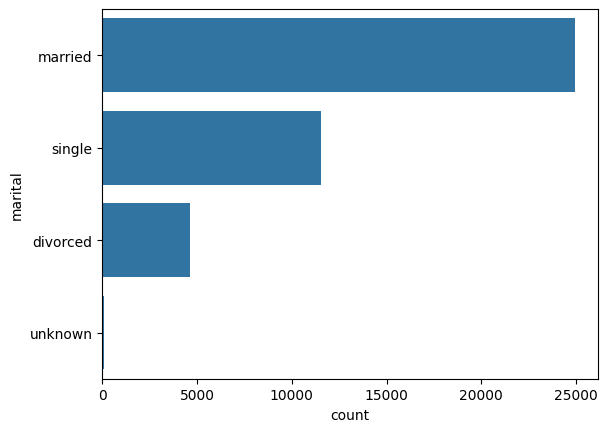

In [383]:
sns.countplot(data=df, y="marital")

Большинство клиентов - в браке

<Axes: xlabel='count', ylabel='education'>

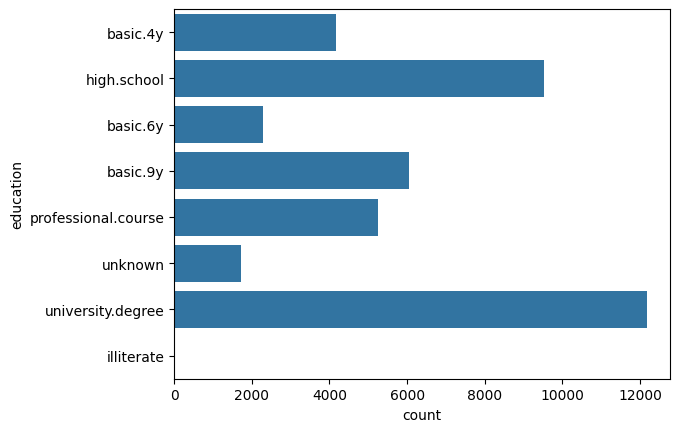

In [384]:
sns.countplot(data=df, y="education")

Большинство клиентов закончили старшую школу или университет

<Axes: xlabel='count', ylabel='default'>

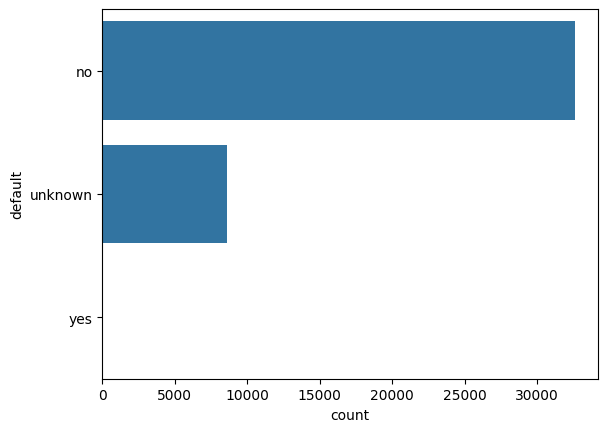

In [385]:
sns.countplot(data=df, y="default")

У большинства клиентов нет просроченного кредита 

<Axes: xlabel='count', ylabel='housing'>

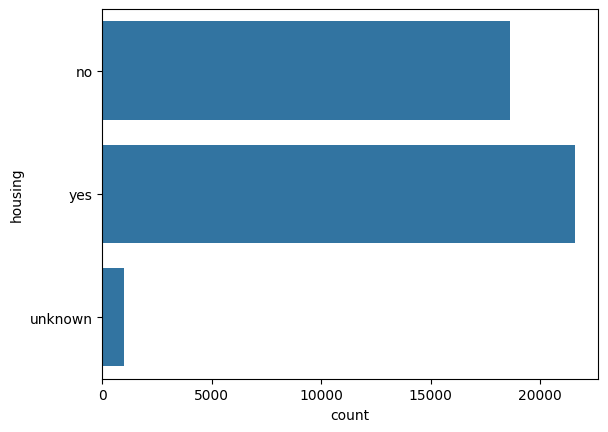

In [386]:
sns.countplot(data=df, y="housing")

У большинства клиентов есть ипотечный кредит, однако здесь нет сильного доминирования одного значения 

<Axes: xlabel='count', ylabel='loan'>

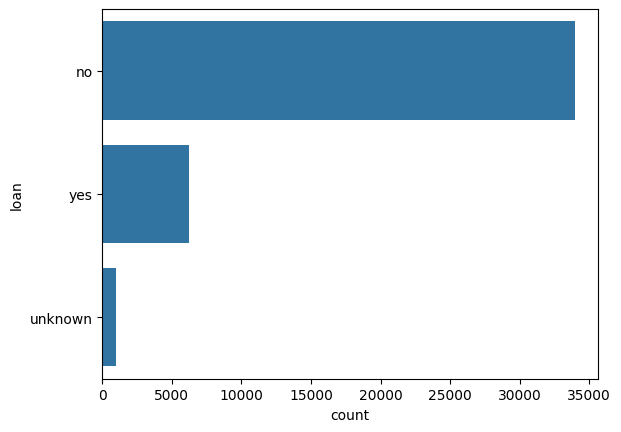

In [387]:
sns.countplot(data=df, y="loan")

У большинства клиентов нет потребительского кредита

<Axes: xlabel='count', ylabel='contact'>

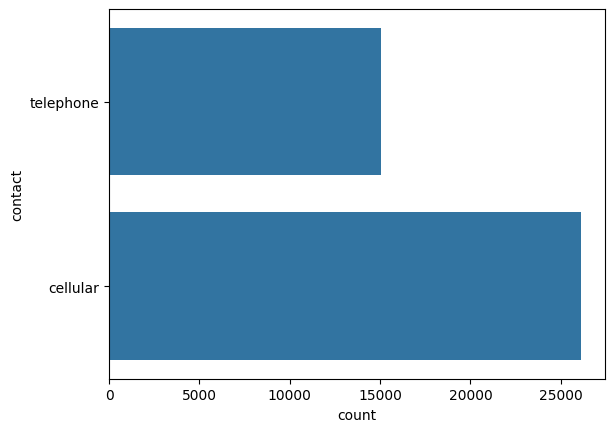

In [388]:
sns.countplot(data=df, y="contact")

В большинстве случаев связь с клиентом происходит по сотовой связи

<Axes: xlabel='count', ylabel='month'>

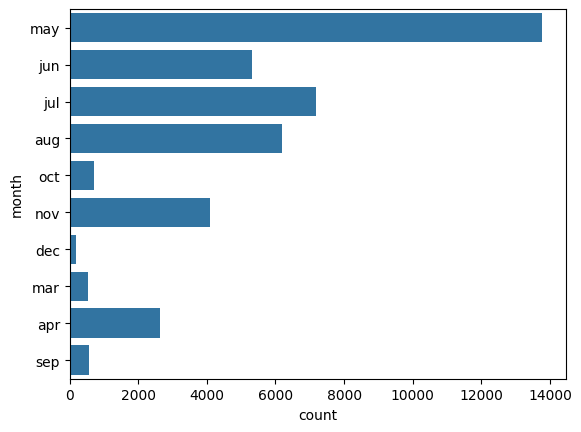

In [389]:
sns.countplot(data=df, y="month")

В большинстве случаев последний месяц контакта с клиентом - май 

<Axes: xlabel='count', ylabel='day_of_week'>

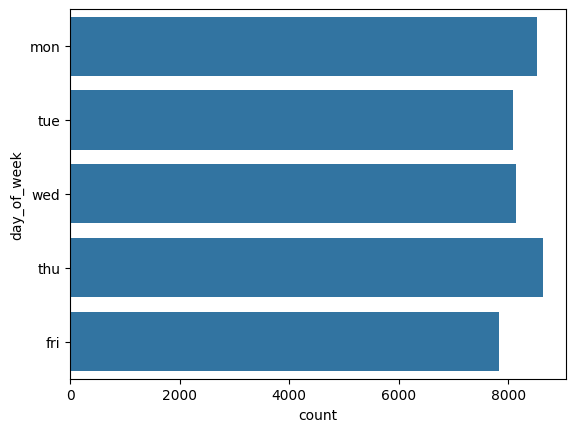

In [390]:
sns.countplot(data=df, y="day_of_week")

День недели последнего контакта с клиентом приблизительно везде одинаковый

<Axes: xlabel='count', ylabel='poutcome'>

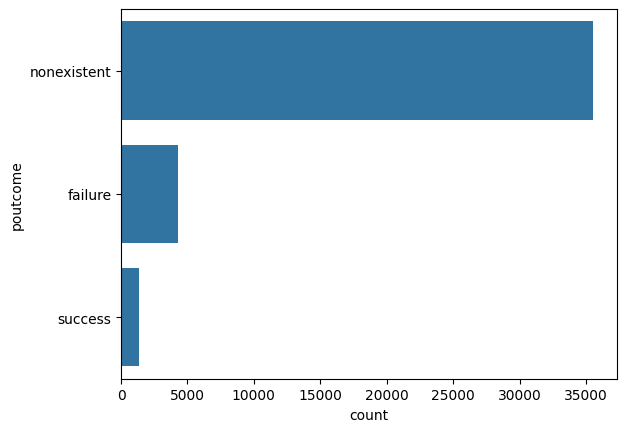

In [391]:
sns.countplot(data=df, y="poutcome")

В основном информация о предыдущей кампании по клиентам отсутствует 

<Axes: xlabel='count', ylabel='y'>

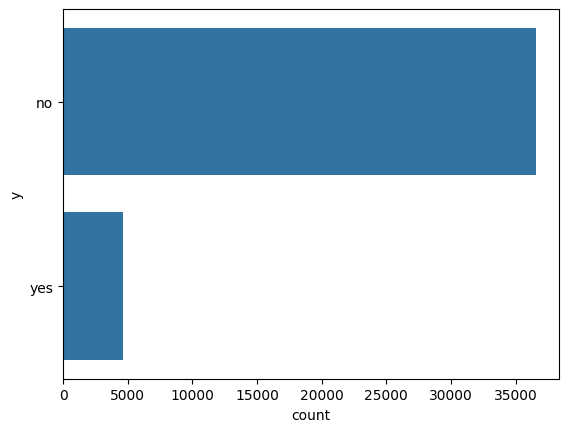

In [392]:
sns.countplot(data=df, y="y")

In [393]:
df["y"].value_counts(normalize=True)

y
no     0.887346
yes    0.112654
Name: proportion, dtype: float64

В таргете виден сильный дизбаланс (1 к 8), большая часть клиентов отказалась оформлять депозит в банке 

4. Изучение взаимосвязей между признаками

4.1 Общая матрица корреляций

Теперь наша цель состоит в том, чтобы проанализировать матрицу корреляций, найди пары признаков, которые коррелируют друг с другом сильнее всего
и проанализировать их. Также нужно посмотреть какие признаки сильнее всего коррелируют с таргетом

/Users/karimildarovic/Задание_классификация/venv/lib/python3.9/site-packages/phik/data_quality.py:59: UserWarning: The number of unique values of variable duration is large: 1544. Are you sure this is not an interval variable? Analysis for pairs of variables including duration can be slow.
  warnings.warn(


<Axes: >

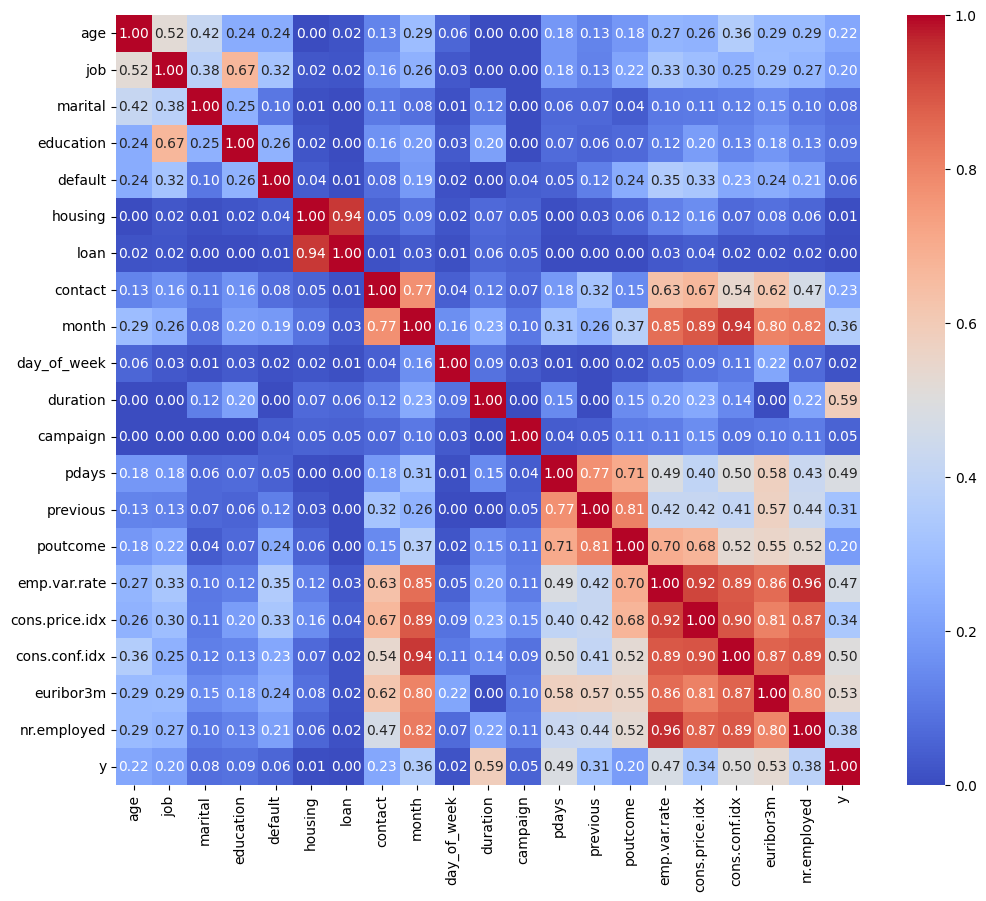

In [394]:
phik_matrix = df.phik_matrix(interval_cols=["age", "campaign", "pdays", "previous", "emp.var.rate", "cons.price.idx", 
"cons.conf.idx", "euribor3m", "nr.employed"])

plt.figure(figsize=(12, 10))
sns.heatmap(phik_matrix, annot=True, fmt=".2f", cmap="coolwarm")

Пары с высоким значением корреляции:
- job vs education
- housing vs loan
- contact vs month, (emp.var.rate, cons.price.idx, cons.conf.idx, euribor3am, nr.employed)
- pdays vs previous
- pdays vs poutcome
- previous vs poutcome
- poutcome vs cons.price.idx
- emp.var.rate vs (cons.price.idx, cons.conf.idx, euribor3am, nr.employed)
- cons.price.idx vs (cons.conf.idx, euribor3am, nr.employed)
- cons.conf.idx vs (euribor3am, nr.employed)
- euribor3m vs nr.employed

Таргет ни с кем сильно не коррелирует

4.2 Подробное изучение корреляций между выбранными парами

<Axes: xlabel='count', ylabel='job'>

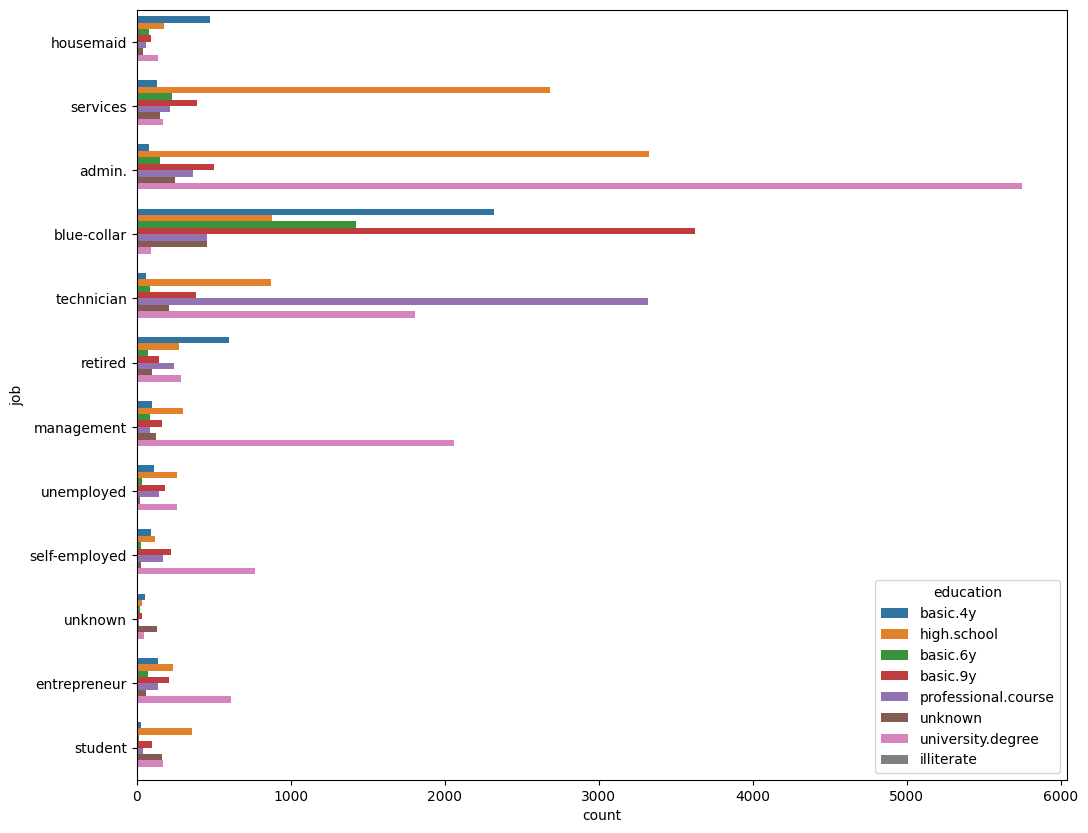

In [395]:
plt.figure(figsize=(12, 10))
sns.countplot(data=df, y="job", hue="education")

Связь между профессией и образованием подтвердилась: например у admin в основном высшее образование, у рабочих только 9 классов образования и тд, в каждой группе преобладаает какой-то определенный 
уровень образования

<Axes: xlabel='count', ylabel='housing'>

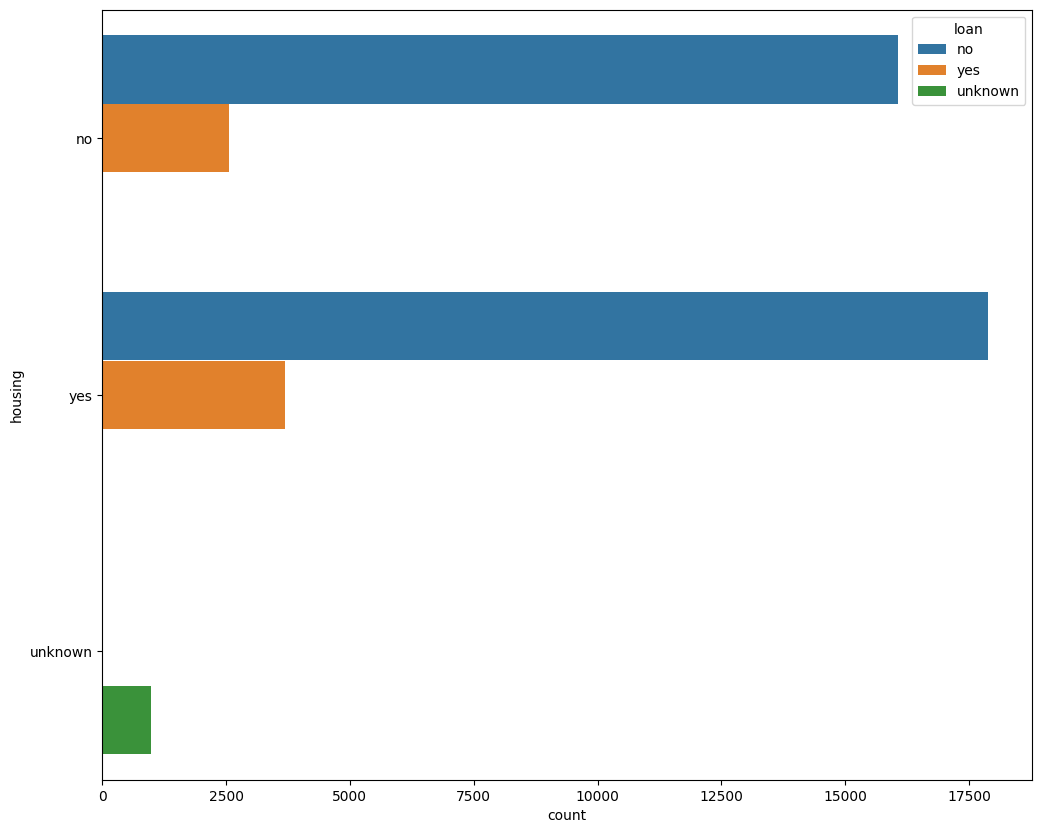

In [396]:
plt.figure(figsize=(12, 10))
sns.countplot(data=df, y="housing", hue="loan")

Графики похожи, то есть доля людей с ипотечным и потребительским кредитом примерно одинакова

<Axes: xlabel='count', ylabel='contact'>

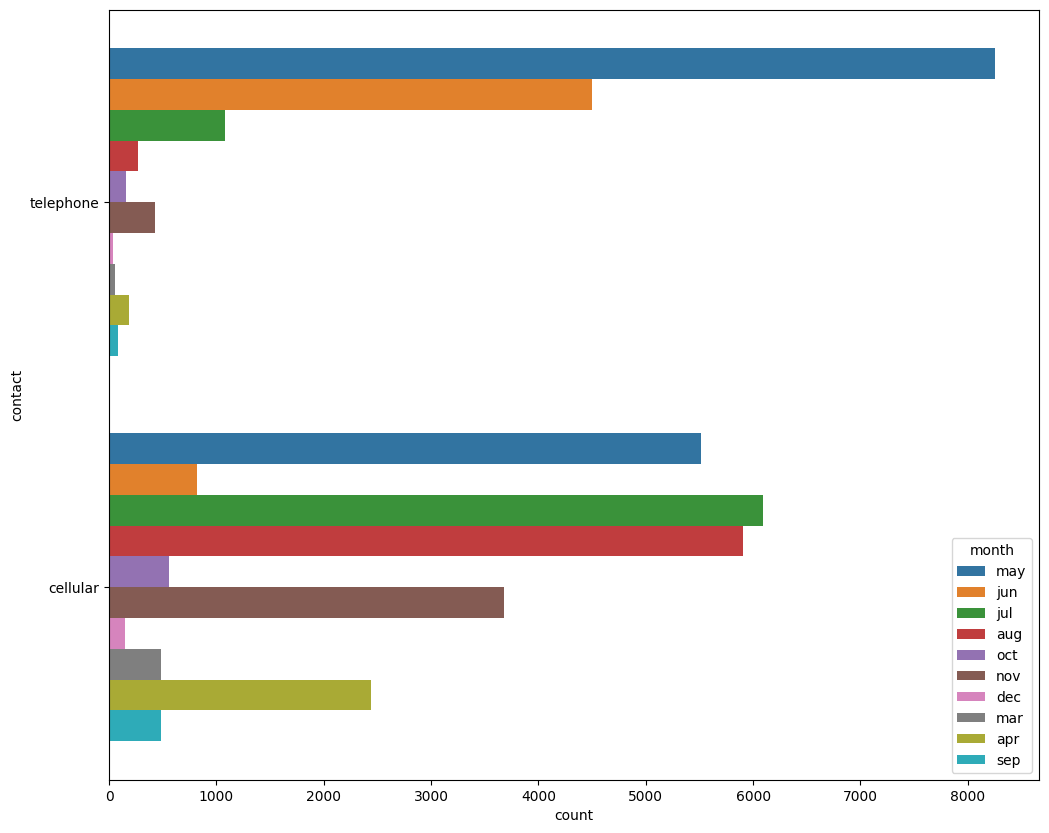

In [397]:
plt.figure(figsize=(12, 10))
sns.countplot(data=df, y="contact", hue="month")

В обоих видах связи преобладает 1-2 месяца. По сути month это признак, связанный со временем, значит и contact тоже меняется во времени. 

<Axes: xlabel='count', ylabel='contact'>

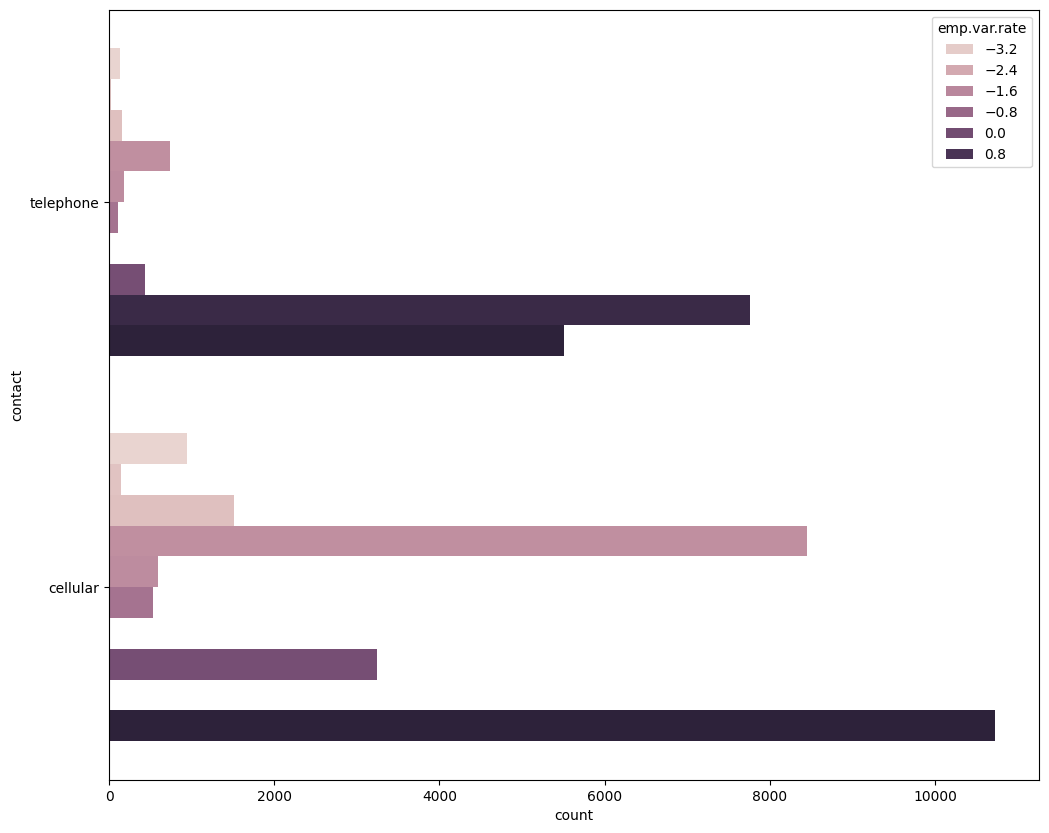

In [398]:
plt.figure(figsize=(12, 10))
sns.countplot(data=df, y="contact", hue="emp.var.rate")

Contact сильно коррелирует с признаками макроэкономической группы (emp.var.rate, cons.price.idx, cons.conf.idx, euribor3am, nr.employed) . По сути можно рассмотреть только одну пару, так как contact сильно коррелирует со всеми этими признаками. Уже понятно, что contact меняется в зависимости от экономической ситуации. Например, тут видно, что если уровень занятости растет, то количество звонков с обоих видов связи растет. Банк понимает, что у людей есть деньги, которые можно вложить. 

<Axes: xlabel='previous', ylabel='pdays'>

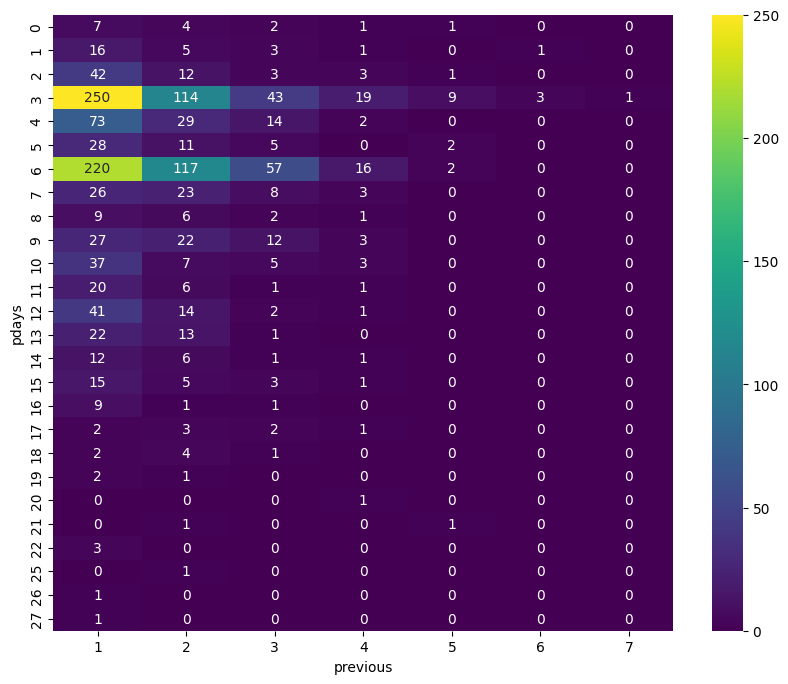

In [399]:
ct = pd.crosstab(df[df["pdays"]!=999]["pdays"], df[df["pdays"]!=999]["previous"]) #убираем заглушку перед построением
plt.figure(figsize=(10, 8))
sns.heatmap(ct, annot=True, fmt="d", cmap="viridis")

Корреляция между признаками pdays и previous подтвердилась, максимальное число клиентов имело контакт с банком 3-6 дней назад, 
при этом с этими же клиентами банк контактировал 1-2 раза в прошлой кампании 

<Axes: xlabel='poutcome', ylabel='pdays'>

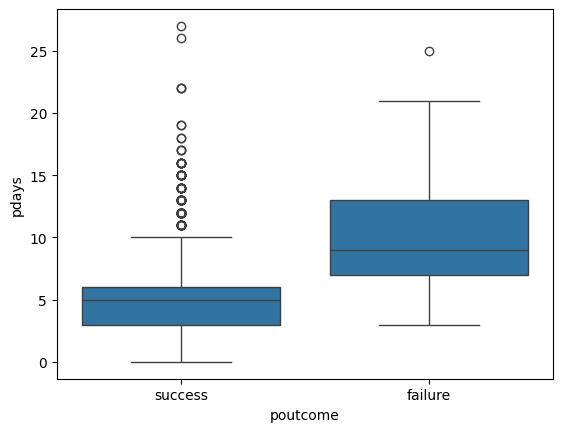

In [400]:
#тут так же ставим заглушку для pdays = 999
sns.boxplot(data=df[df["pdays"] != 999], x="poutcome", y="pdays")

Здесь можем видеть, что успех или провал прошлой кампании для клиента коррелирует с количеством дней последнего контакта с клиентом, 
то есть если pdays примерно 3-6, то скорее всего будет success, если pdays 7-12, то скорее всего будет failure

<Axes: xlabel='poutcome', ylabel='previous'>

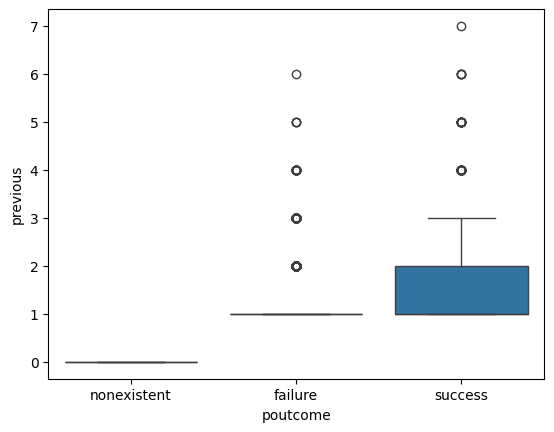

In [401]:
sns.boxplot(data=df, x="poutcome", y="previous")

<Axes: xlabel='poutcome', ylabel='cons.price.idx'>

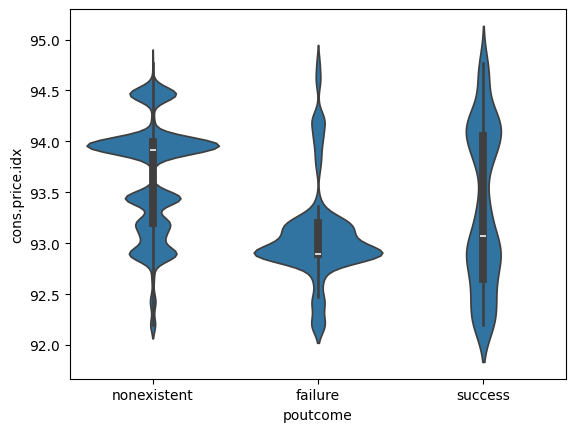

In [402]:
sns.violinplot(data=df, x="poutcome", y="cons.price.idx")

Видно, что разные исходы прошлой компании концентрируются на разных значениях cons.price.idx. Boxplot не выявил такой связи, в то время как violinplot ее показал

<Axes: xlabel='cons.price.idx', ylabel='emp.var.rate'>

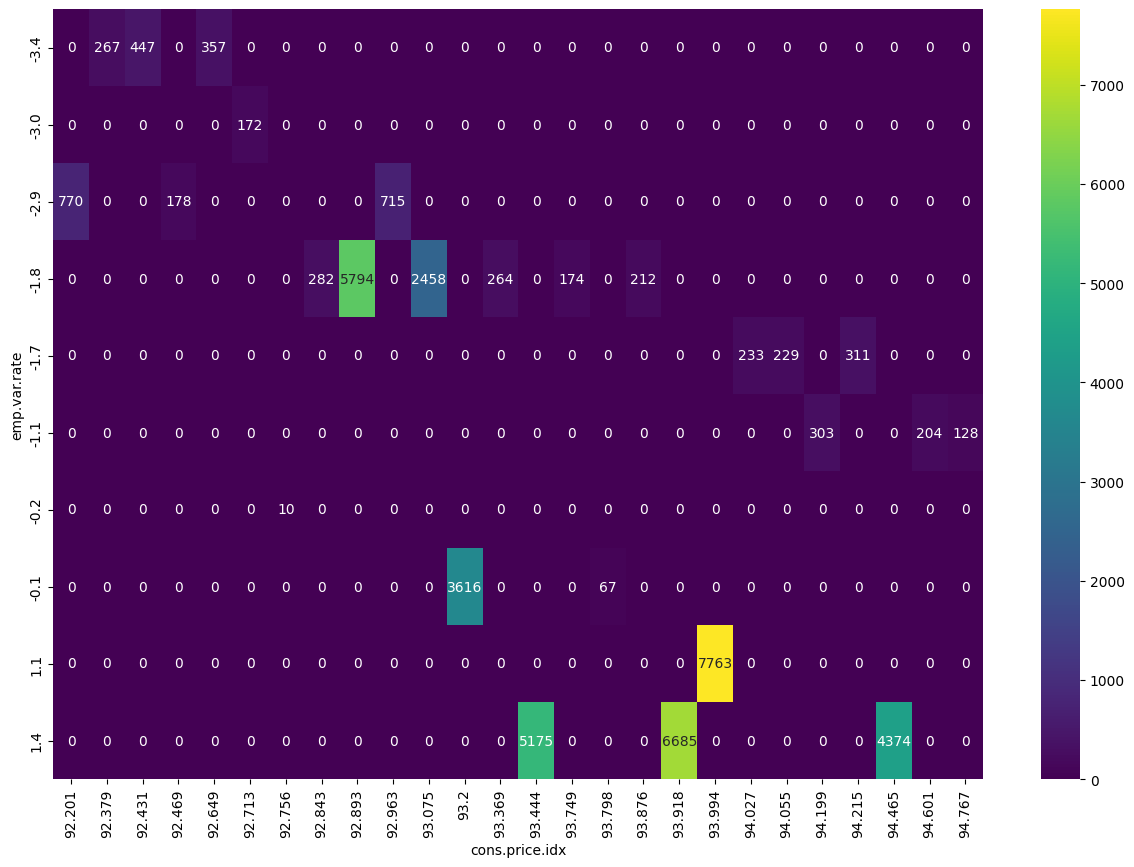

In [403]:
plt.figure(figsize=(15, 10))
ct = pd.crosstab(df["emp.var.rate"], df["cons.price.idx"])
sns.heatmap(ct, annot=True, fmt="d", cmap="viridis")


 Оба признака привязаны ко времени и относятся к группе макроэкономических. Мы видим, что в каждой строке есть пару ненулевых ячеек, остальные нулевые, 
 ненулевые ячейки отражают каждый квартал/месяц экономики. Значит очевидно эти признаки сильно коррелированы. 

Остальные пары макроэкономической группы рассматривать нет смысла, так как они и так связаны между собой временем, так как все эти фичи являются временными

5. Препроцессинг данных

5.1 Общие преобразования 

In [404]:
df_preprocessed = df.copy()

In [405]:
#Кодируем таргет
df_preprocessed["y"] = np.where(df_preprocessed["y"] == "yes", 1, 0)

In [406]:
#Удаляем признак, несущий утечку данных
df_preprocessed = df_preprocessed.drop(columns=['duration']) 

In [407]:
#pdays можно заменить на бинарный признак был/не был контакт 
df_preprocessed["pdays"] = np.where(df_preprocessed["pdays"] != 999, 1, 0)

In [408]:
#Удаляем дубликаты
df_preprocessed.drop_duplicates(inplace=True)

In [409]:
#Теперь нужно найти признаки с unknown 
unknown_counts = (df_preprocessed == 'unknown').sum()
print(unknown_counts[unknown_counts > 0])




job           325
marital        78
education    1686
default      8266
housing       980
loan          980
dtype: int64


Теперь нужно заменить unknown на NaN

In [410]:
df_preprocessed = df_preprocessed.replace('unknown', np.nan)

Теперь перед разбиением датасета нужно понять упорядочены ли данные по времени, это можно определеить, например, по признаку month 


<Axes: >

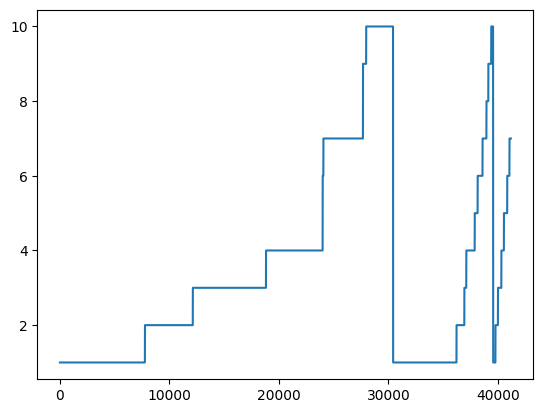

In [411]:
order = {'may':1,'jun':2,'jul':3,'aug':4,'sep':5,'oct':6,'nov':7,'dec':8,'mar':9,'apr':10}
df["month"].map(order).plot()

Здесь мы видим, что месяцы идут лесенкой вверх внутри каждого года, затем сброс = смена года. Это доказывает упорядоченность данных

5.2 Разбиение датасета

In [412]:
#Мы не используем KFold/StratifiedKFold, так как оно перемешивает и берет случайные фолды => это обучение на будущем внутри CV
X = df_preprocessed.drop(columns=['y'])
y = df_preprocessed['y']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

#Для CV будет использоваться TimeSeriesSplit внутри X_train, y_train

In [413]:
X_train

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,1,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
1,57,services,married,high.school,NaN,no,no,telephone,may,mon,1,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
2,37,services,married,high.school,no,yes,no,telephone,may,mon,1,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,1,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
4,56,services,married,high.school,no,no,yes,telephone,may,mon,1,0,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33151,40,services,divorced,high.school,no,no,no,cellular,may,tue,1,0,0,nonexistent,-1.8,92.893,-46.2,1.291,5099.1
33152,34,technician,single,university.degree,no,no,no,cellular,may,tue,1,0,0,nonexistent,-1.8,92.893,-46.2,1.291,5099.1
33153,31,blue-collar,single,basic.9y,no,no,no,cellular,may,tue,5,0,0,nonexistent,-1.8,92.893,-46.2,1.291,5099.1
33154,38,services,single,basic.9y,no,no,yes,cellular,may,tue,1,0,1,failure,-1.8,92.893,-46.2,1.291,5099.1


In [414]:
X_train_preprocessed = X_train.copy()

In [415]:
categorical_cols = ['job', 'marital', 'default', 'housing', 'loan', 'education', 'contact', 'month', 'day_of_week', 'poutcome']
numerical_cols = ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 
'cons.conf.idx', 'euribor3m', 'nr.employed']

5.3 Обработка пропущенных значений 

In [416]:
#Пропуски в этих колонках будут заполняться наиболее частыми значениями

most_frequent_cat_cols = ['job', 'marital', 'education', 'loan', 'housing', 'default']

"""насчет default возможно придется вернуть unknown, так как там 21% пропусков, заполнение модой может исказить признак. Возможно в improvements 
придется вернуть unknown для этого признака"""




'насчет default возможно придется вернуть unknown, так как там 21% пропусков, заполнение модой может исказить признак. Возможно в improvements \nпридется вернуть unknown для этого признака'

In [417]:
#Заменяем пропуски на самое частое значение
most_frequent_inputer = SimpleImputer(strategy="most_frequent")

X_train_preprocessed[most_frequent_cat_cols] = most_frequent_inputer.fit_transform(X_train_preprocessed[most_frequent_cat_cols])

In [418]:
X_train_preprocessed.info()

<class 'pandas.core.frame.DataFrame'>
Index: 31516 entries, 0 to 33155
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             31516 non-null  int64  
 1   job             31516 non-null  object 
 2   marital         31516 non-null  object 
 3   education       31516 non-null  object 
 4   default         31516 non-null  object 
 5   housing         31516 non-null  object 
 6   loan            31516 non-null  object 
 7   contact         31516 non-null  object 
 8   month           31516 non-null  object 
 9   day_of_week     31516 non-null  object 
 10  campaign        31516 non-null  int64  
 11  pdays           31516 non-null  int64  
 12  previous        31516 non-null  int64  
 13  poutcome        31516 non-null  object 
 14  emp.var.rate    31516 non-null  float64
 15  cons.price.idx  31516 non-null  float64
 16  cons.conf.idx   31516 non-null  float64
 17  euribor3m       31516 non-null  floa

In [419]:
X_train_preprocessed.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
dtype: int64

5.2 Кодирование категориальных признаков

In [420]:
#One_hot для job, marital, poutcome, day_of_week, month

onehot_cols = ['job', 'marital', 'poutcome', 'day_of_week', 'month']

for col in onehot_cols:
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False) #создаем кодировщик
    encoded = ohe.fit_transform(X_train_preprocessed[[col]]) #запоминаем и превращаем col в 0/1 столбцы
    cols = ohe.get_feature_names_out([col]) #получаем имена новых столбцов
    encoded = pd.DataFrame(encoded, columns=cols, index=X_train_preprocessed.index) #оборачиваем массив в DataFrame
    X_train_preprocessed = pd.concat([X_train_preprocessed.drop(columns=[col]), encoded], axis=1) #выкидываем старый столбец и приклеиваем новые столбцы

In [421]:
#Ordinal encoding для education, default, housing, loan, contact
ordinal_cols = ['education', 'default', 'housing', 'loan', 'contact']

category_orders = [
    ['illiterate', 'basic.4y', 'basic.6y', 'basic.9y', 'high.school', 'professional.course', 'university.degree'],
    ['no', 'yes'],
    ['no', 'yes'],
    ['no', 'yes'],
    ['cellular', 'telephone']
]

encoder = OrdinalEncoder(categories=category_orders)
X_train_preprocessed[ordinal_cols] = encoder.fit_transform(X_train_preprocessed[ordinal_cols])

In [422]:
X_train_preprocessed

,age,education,default,housing,loan,contact,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,job_admin.,job_blue-collar,job_entrepreneur,job_housemaid,job_management,job_retired,job_self-employed,job_services,job_student,job_technician,job_unemployed,marital_divorced,marital_married,marital_single,poutcome_failure,poutcome_nonexistent,poutcome_success,day_of_week_fri,day_of_week_mon,day_of_week_thu,day_of_week_tue,day_of_week_wed,month_apr,month_aug,month_dec,month_jul,month_jun,month_mar,month_may,month_nov,month_oct
0,56,1.0,0.0,0.0,0.0,1.0,1,0,0,1.1,93.994,-36.4,4.857,5191.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
1,57,4.0,0.0,0.0,0.0,1.0,1,0,0,1.1,93.994,-36.4,4.857,5191.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,37,4.0,0.0,1.0,0.0,1.0,1,0,0,1.1,93.994,-36.4,4.857,5191.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3,40,2.0,0.0,0.0,0.0,1.0,1,0,0,1.1,93.994,-36.4,4.857,5191.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4,56,4.0,0.0,0.0,1.0,1.0,1,0,0,1.1,93.994,-36.4,4.857,5191.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33151,40,4.0,0.0,0.0,0.0,0.0,1,0,0,-1.8,92.893,-46.2,1.291,5099.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
33152,34,6.0,0.0,0.0,0.0,0.0,1,0,0,-1.8,92.893,-46.2,1.291,5099.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
33153,31,3.0,0.0,0.0,0.0,0.0,5,0,0,-1.8,92.893,-46.2,1.291,5099.1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
33154,38,3.0,0.0,0.0,1.0,0.0,1,0,1,-1.8,92.893,-46.2,1.291,5099.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


5.3 Итоговый пайплайн для препроцессинга 

In [423]:
#Список признаков по группам
numeric_cols = ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
onehot_cols  = ['job', 'marital', 'poutcome', 'day_of_week', 'month']
ord_col      = ['education']
binary_cols  = ['default', 'housing', 'loan', 'contact']

In [424]:
#Cоберем все в один ColumnTransformer через мини Pipeline'ы 
ohe_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ohe', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

ord_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ord', OrdinalEncoder(categories=[
        ['illiterate', 'basic.4y', 'basic.6y', 'basic.9y', 'high.school', 'professional.course', 'university.degree']
    ]))
])

bin_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ord', OrdinalEncoder(categories=[
        ['no', 'yes'], #default
        ['no', 'yes'], #housing
        ['no', 'yes'], #loan
        ['cellular', 'telephone'] #contact
    ]))
])

preprocessor = ColumnTransformer([
    ('num', 'passthrough', numeric_cols),
    ('ohe', ohe_pipe, onehot_cols),
    ('ord', ord_pipe, ord_col),
    ('bin', bin_pipe, binary_cols),
])
preprocessor.set_output(transform="pandas")

ColumnTransformer(transformers=[('num', 'passthrough',
                                 ['age', 'campaign', 'pdays', 'previous',
                                  'emp.var.rate', 'cons.price.idx',
                                  'cons.conf.idx', 'euribor3m',
                                  'nr.employed']),
                                ('ohe',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ohe',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['job', 'marital', 'poutcome', 'day_of_week...
                                                  OrdinalEncoder(categories=[['illiterate',
                                                                              'basic.4y',
                                                                              'basic.6y',
                                                                              'basic.9y',
                                                                              'high.school',
                                                                              'professional.course',
                                                                              'university.degree']]))]),
                                 ['education']),
                                ('bin',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('ord',
                                                  OrdinalEncoder(categories=[['no',
                                                                              'yes'],
                                                                             ['no',
                                                                              'yes'],
                                                                             ['no',
                                                                              'yes'],
                                                                             ['cellular',
                                                                              'telephone']]))]),
                                 ['default', 'housing', 'loan', 'contact'])])

In [425]:
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_train_preprocessed = pd.DataFrame(X_train_preprocessed, index=X_train.index)

In [426]:
X_train_preprocessed

,num__age,num__campaign,num__pdays,num__previous,num__emp.var.rate,num__cons.price.idx,num__cons.conf.idx,num__euribor3m,num__nr.employed,ohe__job_admin.,ohe__job_blue-collar,ohe__job_entrepreneur,ohe__job_housemaid,ohe__job_management,ohe__job_retired,ohe__job_self-employed,ohe__job_services,ohe__job_student,ohe__job_technician,ohe__job_unemployed,ohe__marital_divorced,ohe__marital_married,ohe__marital_single,ohe__poutcome_failure,ohe__poutcome_nonexistent,ohe__poutcome_success,ohe__day_of_week_fri,ohe__day_of_week_mon,ohe__day_of_week_thu,ohe__day_of_week_tue,ohe__day_of_week_wed,ohe__month_apr,ohe__month_aug,ohe__month_dec,ohe__month_jul,ohe__month_jun,ohe__month_mar,ohe__month_may,ohe__month_nov,ohe__month_oct,ord__education,bin__default,bin__housing,bin__loan,bin__contact
0,56,1,0,0,1.1,93.994,-36.4,4.857,5191.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
1,57,1,0,0,1.1,93.994,-36.4,4.857,5191.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4.0,0.0,0.0,0.0,1.0
2,37,1,0,0,1.1,93.994,-36.4,4.857,5191.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4.0,0.0,1.0,0.0,1.0
3,40,1,0,0,1.1,93.994,-36.4,4.857,5191.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,2.0,0.0,0.0,0.0,1.0
4,56,1,0,0,1.1,93.994,-36.4,4.857,5191.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4.0,0.0,0.0,1.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
33151,40,1,0,0,-1.8,92.893,-46.2,1.291,5099.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,4.0,0.0,0.0,0.0,0.0
33152,34,1,0,0,-1.8,92.893,-46.2,1.291,5099.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0
33153,31,5,0,0,-1.8,92.893,-46.2,1.291,5099.1,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0
33154,38,1,0,1,-1.8,92.893,-46.2,1.291,5099.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,3.0,0.0,0.0,1.0,0.0
